# Following concept groups over time

This notebook extends **`concept_agreement_study.executed.ipynb`**, whose main run completed on Fiji
on November 6, 2026. The interpretation below also considers its sensitivity-scale follow-up reviewed
on November 8, 2026.
It asks whether fixed groups of factors show temporal behavior that their individual factors miss:
representation across dictionaries, local sensitivity, and changes alongside current model performance.

The predictor, reference dictionaries, factor groups, rules and activation cutoffs stay fixed.
The original notebook and its results are read-only inputs. This report reads new aggregate results;
it does not rerun or modify the completed experiment.

**Primary context:** the last three years. **Companion context:** all previous years.
Embeddings are followed through 2015; mortality outcomes are used only through 2014.

The source inventory contains **95 distinct concepts in 11 reference builds**. Exactly **92 concepts**
have saved group definitions, giving **276 seed-pair comparisons**. Three source concepts have no
frozen group definition and remain explicit gaps; the actual run coverage is shown below.

## Read the completed extension

Set `CONCEPT_GROUPS_RESULTS` to a specific result directory to review that run. Otherwise the notebook
selects the newest **completed full evaluation** under `analysis_outputs/concept_groups_over_time/`.
Inventory-only commands and smoke checks are excluded from automatic selection. An explicitly selected smoke check is displayed
with a warning throughout: it validates calculations and provides no full-study conclusions.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import JSON, Markdown, display

from concept_groups_over_time import load_report

result_root = Path.cwd() / "analysis_outputs" / "concept_groups_over_time"
requested_result = os.environ.get("CONCEPT_GROUPS_RESULTS")

if requested_result:
    result_directory = Path(requested_result).expanduser().resolve()
else:
    completed_results = []
    for manifest_path in result_root.glob("*/run-manifest.json"):
        candidate = json.loads(manifest_path.read_text())
        if (
            candidate.get("status") == "completed"
            and not candidate.get("smoke", False)
            and candidate.get("config", {}).get("command") == "evaluate"
        ):
            completed_results.append(manifest_path)
    if not completed_results:
        raise FileNotFoundError(
            "No completed full extension exists yet. Smoke checks validate calculations, "
            "not scientific conclusions. Set CONCEPT_GROUPS_RESULTS explicitly to inspect "
            "a smoke check, or run the approved full evaluation first."
        )
    result_directory = max(completed_results, key=lambda path: path.stat().st_mtime).parent

manifest = json.loads((result_directory / "run-manifest.json").read_text())
if manifest.get("status") != "completed":
    raise ValueError("Select a completed run; incomplete outputs cannot support this report.")
is_smoke = bool(manifest.get("smoke", False))
run_command = manifest.get("config", {}).get("command")
if run_command == "inventory":
    raise ValueError(
        "An inventory lists available inputs and has no temporal results. "
        "Select a completed evaluation, or explicitly select a smoke check."
    )
if run_command not in ("evaluate", "smoke"):
    raise ValueError("Select a result manifest whose command is evaluate or smoke.")
if run_command == "smoke" and not is_smoke:
    raise ValueError("A smoke command must carry its smoke flag; inspect the manifest.")
report = load_report(result_directory)

pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

report_label = "SMOKE CHECK — no full-study conclusions" if is_smoke else "Completed temporal study"
display(Markdown(f"**{report_label}**"))
print("Results:", result_directory)
print("Status:", manifest["status"])

**Completed temporal study**

Results: /home/rafaelgomes/SAE-TCAV/analysis_outputs/concept_groups_over_time/20261108-full
Status: completed


## What is being measured?

A factor contributes its activation times its decoder direction, expressed in the predictor's raw
embedding coordinates. A group's contribution is the sum of its members' contributions.

| Quantity | Meaning | Reading it correctly |
|---|---|---|
| Contribution disagreement | Squared difference between two seeds' represented contributions, divided by their combined squared size | Lower means the dictionaries represent a more similar vector; it does not establish the group's meaning |
| Loading, **S** | Death-probability gradient dotted with the contribution | A local first-order quantity that includes activation strength; positive points toward higher predicted mortality |
| Directional sensitivity, **T** | Loading divided by contribution norm | Controls contribution magnitude; undefined for zero or cancelled vectors |
| Cancellation | How much the summed vector shrinks relative to the sum of member vector sizes | A stable group can conceal opposing members; inspect constituents too |
| Brier score | Mean squared difference between predicted mortality probability and outcome | Lower is better; outcomes stop in 2014 |

Neither loading nor directional sensitivity is TCAV or an actual factor-removal effect. No group CAV
is fitted. Grouping also leaves every patient's frozen prediction unchanged: on identical patients,
**group and individual descriptions have the same Brier score**.

Original patient groups are retained: **activation group** means above the original factor cutoff;
**rule group** means matching its original rule; **all** means all evaluation patients.
There is no newly learned group threshold.

Intervals use **500 joint patient-bootstrap draws**, conditional on all frozen objects. Each patient's
resampling weight is shared across years, families, dictionaries and controls. The source study used
1,000 draws; this extension's approved design uses 500. Related families are not independent replications.

The source notebook measures sensitivity along fitted CAV directions. Here both groups and their
individual anchors are measured using the same decoder-contribution definitions above. Values are
not numerically interchangeable with the source CAV sensitivities.

**Both S and T use the gradient of death probability.** For predicted probability *p*, the relationship
is **probability gradient = p(1 − p) × log-odds gradient**. Log odds means the logarithm of the odds
*p / (1 − p)*. Dividing by contribution norm controls the contribution's size; it does not remove the
*p(1 − p)* factor. Thus neither loading nor unit-normalized directional sensitivity removes this
probability-scale dependence. This extension does not compute a log-odds sensitivity variant.

In [2]:
# Presentation labels only: the scientific tables and calculations stay unchanged.
concept_order = report["inventory"][["concept", "reference"]].drop_duplicates()
concept_order = concept_order.sort_values(["reference", "concept"])
concept_number = concept_order.groupby("reference").cumcount() + 1
concept_labels = {
    row.concept: f"Reference {int(row.reference)}, concept {number}"
    for row, number in zip(concept_order.itertuples(index=False), concept_number)
}
concept_labels["pooled"] = "All concepts"
pair_labels = {
    pair: f"Comparison {number}"
    for number, pair in enumerate(sorted(report["inventory"]["pair"].unique()), start=1)
}
context_labels = {"last_3": "Last 3 years", "all_history": "All previous years"}
method_labels = {
    "selected": "Selected group", "singleton": "Individual anchor",
    "control_1": "Matched control 1", "control_2": "Matched control 2",
    "control_3": "Matched control 3",
}
patient_group_labels = {
    "all": "All evaluation patients", "A": "Original activation group", "R": "Original rule group",
}
measure_labels = {
    "E": "Contribution disagreement",
    "absolute_loading": "Mean absolute loading",
    "signed_loading": "Mean signed loading",
    "absolute_direction": "Mean absolute directional sensitivity (own active patients)",
    "common_active_absolute_direction": "Mean absolute directional sensitivity (common active patients)",
    "delta_singleton": "Disagreement minus individual anchor",
    "delta_selected": "Disagreement minus selected group",
    "selected_minus_singleton_E": "Selected group minus individual anchor disagreement",
    "selected_minus_control_1_E": "Selected group minus matched control 1 disagreement",
    "selected_minus_control_2_E": "Selected group minus matched control 2 disagreement",
    "selected_minus_control_3_E": "Selected group minus matched control 3 disagreement",
    "spearman": "Rank correlation",
    "median_of_dependent_case_means": "Median across related comparisons",
    "case_mean_over_later_years": "Average over later years for this comparison",
    "within_concept_changes": "Year-to-year changes within this concept",
    "pooled_changes": "Year-to-year changes across concepts",
    "none": "No adjustment",
    "family_and_year": "Adjusted for concept and year",
    "mortality_risk_and_support": "Adjusted for mortality, mean risk and subgroup size",
    "family_year_mortality_and_support": "Adjusted for concept, year, mortality and subgroup size",
    "family_year_mortality_risk_and_support": "Also adjusted for mean predicted risk",
}


def readable_table(table):
    """Copy an aggregate table with readable labels; keep raw identifiers in the appendix."""
    shown = table.drop(columns=["key", "family", "build"], errors="ignore").copy()
    if "concept" in shown:
        shown["concept"] = shown["concept"].map(concept_labels)
    if "pair" in shown:
        shown["pair"] = shown["pair"].map(pair_labels)
    for column in ("variants", "variant"):
        if column in shown:
            shown[column] = shown[column].map(
                lambda value: ", ".join(context_labels.get(part, part) for part in str(value).split(","))
                if pd.notna(value) else value
            )
    for column, labels in (("kind", method_labels), ("subgroup", patient_group_labels)):
        if column in shown:
            shown[column] = shown[column].replace(labels)
    if "side" in shown:
        shown["side"] = shown["side"].replace({"left": "First dictionary", "right": "Second dictionary"})
    if "transition" in shown:
        shown["transition"] = shown["transition"].astype(str).replace({
            "11": "Stayed in subgroup", "10": "Left subgroup",
            "01": "Entered subgroup", "00": "Stayed outside subgroup",
            "1": "Entered subgroup", "0": "Stayed outside subgroup",
        })
    for column in ("metric", "feature", "target", "adjustment", "level"):
        if column in shown:
            shown[column] = shown[column].map(
                lambda value: measure_labels.get(value, str(value).replace("_", " "))
                if pd.notna(value) else value
            )
    return shown.rename(columns=lambda name: {
        "transitions": "Available year-pairs before missing-value filtering",
        "families": "Concepts in available panel",
    }.get(name, str(name).replace("_", " ").capitalize()))


## Coverage comes first

The morning study and the saved group study have separate inventories. Their exact concept keys are
joined, and missing group definitions stay visible. Unsupported cells are undefined, not zero.
The coverage table shows what was actually scored in this run.

In [3]:
display(Markdown(f"**{report_label}**"))
coverage = pd.DataFrame({
    "Coverage": [
        "Source concepts",
        "Concepts with saved groups",
        "Dictionary pairs with saved groups",
        "Concepts actually scored in this run",
        "Dictionary pairs actually scored in this run",
    ],
    "Count": [
        manifest.get("inventory_concepts"),
        manifest.get("matched_families"),
        manifest.get("matched_pairs"),
        manifest.get("completed_families"),
        manifest.get("completed_pairs"),
    ],
})
display(coverage)
display(Markdown(
    "**Availability and scoring are different.** The inventory lists every source concept "
    "and whether saved groups exist. Only the concepts and dictionary pairs marked "
    "as actually scored contribute results in this run. A smoke check covers a small subset."
))
display(readable_table(report["inventory"]).head(30))

**Completed temporal study**

,Coverage,Count
0,Source concepts,95
1,Concepts with saved groups,92
2,Dictionary pairs with saved groups,276
3,Concepts actually scored in this run,92
4,Dictionary pairs actually scored in this run,276


**Availability and scoring are different.** The inventory lists every source concept and whether saved groups exist. Only the concepts and dictionary pairs marked as actually scored contribute results in this run. A smoke check covers a small subset.

,Concept,Pair,Reference,Selected,Status,Variants
0,"Reference 2008, concept 1",Comparison 2,2008,True,available,"Last 3 years, All previous years"
1,"Reference 2008, concept 1",Comparison 3,2008,True,available,"Last 3 years, All previous years"
2,"Reference 2008, concept 1",Comparison 1,2008,True,available,"Last 3 years, All previous years"
3,"Reference 2008, concept 2",Comparison 2,2008,True,available,"Last 3 years, All previous years"
4,"Reference 2008, concept 2",Comparison 3,2008,True,available,"Last 3 years, All previous years"
5,"Reference 2008, concept 2",Comparison 1,2008,True,available,"Last 3 years, All previous years"
6,"Reference 2008, concept 3",Comparison 2,2008,True,available,"Last 3 years, All previous years"
7,"Reference 2008, concept 3",Comparison 3,2008,True,available,"Last 3 years, All previous years"
8,"Reference 2008, concept 3",Comparison 1,2008,True,available,"Last 3 years, All previous years"
9,"Reference 2008, concept 4",Comparison 2,2008,True,available,"Last 3 years, All previous years"


In [4]:
# Choose one example by structural order, before looking at effect sizes.
annual = report["annual"]
primary_rows = annual[annual["variants"].str.split(",").apply(lambda values: "last_3" in values)]
example_rows = primary_rows.sort_values(["reference", "concept", "pair", "side"])
if example_rows.empty:
    raise ValueError("This run contains no primary-context trajectories to display.")
example = example_rows.iloc[0]
example_concept = example["concept"]
example_pair = example["pair"]
example_side = example["side"]
example_year_values = annual.loc[annual["concept"] == example_concept, "year"]
example_first_year = int(example_year_values.min())
example_last_year = int(example_year_values.max())
example_year_ticks = np.arange(example_first_year, example_last_year + 1)
example_caption = f"{concept_labels[example_concept]}, last 3 years; first case in structural order"
display(Markdown(example_caption))

kind_labels = {
    "selected": "Selected group",
    "singleton": "Individual anchor",
    "control_1": "Matched control 1",
    "control_2": "Matched control 2",
    "control_3": "Matched control 3",
}
subgroup_labels = {"all": "All evaluation patients", "A": "Original activation group", "R": "Original rule group"}

Reference 2007, concept 1, last 3 years; first case in structural order

## Do groups preserve representation over time?

Compare each fixed selected group with its original individual anchor and the three equally searched,
size-matched controls. Inspect the original reference year before reading later years. The primary
comparison averages computable later-year group-minus-anchor disagreement within each case;
negative values favor the group. Show control comparisons separately: a benefit shared by controls
may reflect aggregation rather than family specificity.

**Completed temporal study**

,Concept,Defined draws,High,Kind,Low,Metric,Pair,Reference,Rows,Subgroup,Undefined draw fraction,Value,Variants,Year
0,"Reference 2008, concept 1",500,0.5465,Selected group,0.4883,Contribution disagreement,Comparison 2,2008,298,All evaluation patients,0.0,0.5149,"Last 3 years, All previous years",2008
1,"Reference 2008, concept 1",500,-0.4030,Selected group,-0.4586,Disagreement minus individual anchor,Comparison 2,2008,298,All evaluation patients,0.0,-0.4332,"Last 3 years, All previous years",2008
2,"Reference 2008, concept 1",500,0.0000,Selected group,0.0000,Disagreement minus selected group,Comparison 2,2008,298,All evaluation patients,0.0,0.0000,"Last 3 years, All previous years",2008
3,"Reference 2008, concept 1",500,0.9504,Individual anchor,0.9460,Contribution disagreement,Comparison 2,2008,298,All evaluation patients,0.0,0.9480,"Last 3 years, All previous years",2008
4,"Reference 2008, concept 1",500,0.0000,Individual anchor,0.0000,Disagreement minus individual anchor,Comparison 2,2008,298,All evaluation patients,0.0,0.0000,"Last 3 years, All previous years",2008
5,"Reference 2008, concept 1",500,0.4586,Individual anchor,0.4030,Disagreement minus selected group,Comparison 2,2008,298,All evaluation patients,0.0,0.4332,"Last 3 years, All previous years",2008
6,"Reference 2008, concept 1",500,0.4688,Matched control 1,0.4319,Contribution disagreement,Comparison 2,2008,298,All evaluation patients,0.0,0.4491,"Last 3 years, All previous years",2008
7,"Reference 2008, concept 1",500,-0.4786,Matched control 1,-0.5158,Disagreement minus individual anchor,Comparison 2,2008,298,All evaluation patients,0.0,-0.4990,"Last 3 years, All previous years",2008
8,"Reference 2008, concept 1",500,-0.0425,Matched control 1,-0.0918,Disagreement minus selected group,Comparison 2,2008,298,All evaluation patients,0.0,-0.0658,"Last 3 years, All previous years",2008
9,"Reference 2008, concept 1",500,0.6090,Matched control 2,0.5776,Contribution disagreement,Comparison 2,2008,298,All evaluation patients,0.0,0.5920,"Last 3 years, All previous years",2008


,Cases computable,Cases total,Concept,Defined draws,High,Later years,Level,Low,Metric,Pair,Patient draws shared across cases,Reference,Subgroup,Undefined draw fraction,Value,Variant,Variants
0,NaN,NaN,"Reference 2008, concept 1",500,-0.1800,7.0,Average over later years for this comparison,-0.2005,Selected group minus individual anchor disagre...,Comparison 2,NaN,2008.0,All evaluation patients,0.0,-0.1904,NaN,"Last 3 years, All previous years"
1,NaN,NaN,"Reference 2008, concept 1",500,0.2605,7.0,Average over later years for this comparison,0.2379,Selected group minus matched control 1 disagre...,Comparison 2,NaN,2008.0,All evaluation patients,0.0,0.2489,NaN,"Last 3 years, All previous years"
2,NaN,NaN,"Reference 2008, concept 1",500,0.0513,7.0,Average over later years for this comparison,0.0229,Selected group minus matched control 2 disagre...,Comparison 2,NaN,2008.0,All evaluation patients,0.0,0.0367,NaN,"Last 3 years, All previous years"
3,NaN,NaN,"Reference 2008, concept 1",500,-0.0234,7.0,Average over later years for this comparison,-0.0532,Selected group minus matched control 3 disagre...,Comparison 2,NaN,2008.0,All evaluation patients,0.0,-0.0383,NaN,"Last 3 years, All previous years"
4,NaN,NaN,"Reference 2008, concept 1",500,-0.3593,7.0,Average over later years for this comparison,-0.3762,Selected group minus individual anchor disagre...,Comparison 2,NaN,2008.0,Original activation group,0.0,-0.3690,NaN,"Last 3 years, All previous years"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3331,153.0,153.0,NaN,500,-0.1981,NaN,Median across related comparisons,-0.2199,Selected group minus matched control 1 disagre...,NaN,True,NaN,Original rule group,0.0,-0.2087,All previous years,NaN
3332,180.0,183.0,NaN,500,-0.1583,NaN,Median across related comparisons,-0.1725,Selected group minus matched control 2 disagre...,NaN,True,NaN,Original rule group,0.0,-0.1647,Last 3 years,NaN
3333,153.0,153.0,NaN,500,-0.1742,NaN,Median across related comparisons,-0.1861,Selected group minus matched control 2 disagre...,NaN,True,NaN,Original rule group,0.0,-0.1789,All previous years,NaN
3334,180.0,183.0,NaN,500,-0.1763,NaN,Median across related comparisons,-0.1978,Selected group minus matched control 3 disagre...,NaN,True,NaN,Original rule group,0.0,-0.1813,Last 3 years,NaN


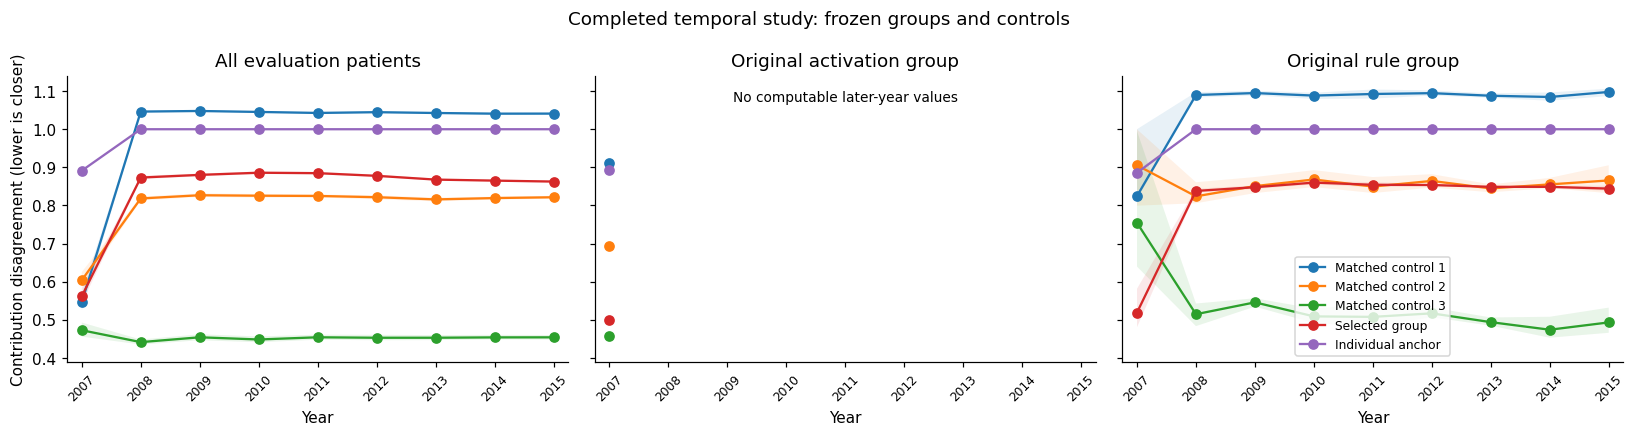

Reference 2007, concept 1, last 3 years; first case in structural order

In [5]:
display(Markdown(f"**{report_label}**"))
display(readable_table(report["representation"]).head(30))
display(readable_table(report["summary"]))

representation = report["representation"]
example_representation = representation[
    (representation["concept"] == example_concept)
    & (representation["pair"] == example_pair)
    & (representation["metric"] == "E")
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for axis, subgroup in zip(axes, ("all", "A", "R")):
    panel = example_representation[example_representation["subgroup"] == subgroup]
    for kind, curve in panel.groupby("kind", sort=True):
        curve = curve.sort_values("year")
        axis.plot(curve["year"], curve["value"], marker="o", label=kind_labels.get(kind, kind))
        axis.fill_between(curve["year"], curve["low"], curve["high"], alpha=0.10)
    axis.set(title=subgroup_labels[subgroup], xlabel="Year")
    axis.set_xlim(example_first_year - 0.25, example_last_year + 0.25)
    axis.set_xticks(example_year_ticks)
    axis.tick_params(axis="x", labelrotation=45, labelsize=8)
    later_values = panel.loc[panel["year"] > example_first_year, "value"]
    if not np.isfinite(later_values).any():
        axis.text(
            0.5, 0.95, "No computable later-year values",
            transform=axis.transAxes, ha="center", va="top", fontsize=9,
        )
axes[0].set_ylabel("Contribution disagreement (lower is closer)")
axes[-1].legend(fontsize=8)
fig.suptitle(f"{report_label}: frozen groups and controls")
fig.tight_layout()
plt.show()
display(Markdown(example_caption))

### Whole-study representation comparison

The panels below show the **primary last-3-years context across all scored concepts**, rather than a
single example. For each concept and dictionary comparison, the saved estimate first averages
computable later-year differences; the displayed point is the median across those related comparisons.
The interval comes from the shared patient draws, not from treating comparisons as independent.

**Negative favors the selected group.** Counts beside each comparison show computable / total cases.
A missing or undefined estimate remains visible. The three matched controls help distinguish a
family-specific gain from a gain also obtainable by combining other factors.

**Completed temporal study**

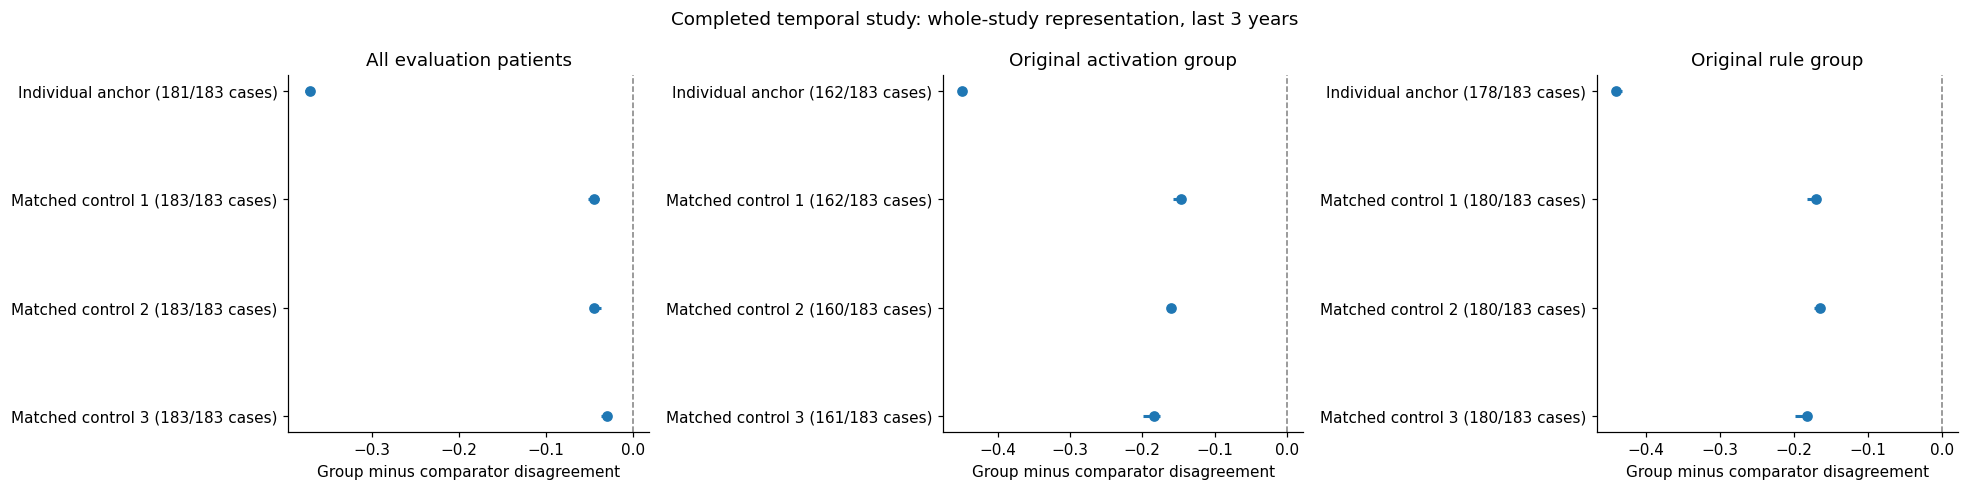

Points are saved estimates; lines are their 95% patient-bootstrap intervals. Negative values favor the selected group. Undefined intervals are not replaced by zero.

,Cases computable,Cases total,Concept,Defined draws,High,Later years,Level,Low,Metric,Pair,Patient draws shared across cases,Reference,Subgroup,Undefined draw fraction,Value,Variant,Variants
3312,181.0,183.0,NaN,500,-0.3666,NaN,Median across related comparisons,-0.3770,Selected group minus individual anchor disagre...,NaN,True,NaN,All evaluation patients,0.0,-0.3704,Last 3 years,NaN
3314,183.0,183.0,NaN,500,-0.0384,NaN,Median across related comparisons,-0.0510,Selected group minus matched control 1 disagre...,NaN,True,NaN,All evaluation patients,0.0,-0.0440,Last 3 years,NaN
3316,183.0,183.0,NaN,500,-0.0362,NaN,Median across related comparisons,-0.0488,Selected group minus matched control 2 disagre...,NaN,True,NaN,All evaluation patients,0.0,-0.0444,Last 3 years,NaN
3318,183.0,183.0,NaN,500,-0.0247,NaN,Median across related comparisons,-0.0365,Selected group minus matched control 3 disagre...,NaN,True,NaN,All evaluation patients,0.0,-0.0299,Last 3 years,NaN
3320,162.0,183.0,NaN,500,-0.4464,NaN,Median across related comparisons,-0.4531,Selected group minus individual anchor disagre...,NaN,True,NaN,Original activation group,0.0,-0.4494,Last 3 years,NaN
3322,162.0,183.0,NaN,500,-0.1408,NaN,Median across related comparisons,-0.1575,Selected group minus matched control 1 disagre...,NaN,True,NaN,Original activation group,0.0,-0.1467,Last 3 years,NaN
3324,160.0,183.0,NaN,500,-0.1551,NaN,Median across related comparisons,-0.1643,Selected group minus matched control 2 disagre...,NaN,True,NaN,Original activation group,0.0,-0.1609,Last 3 years,NaN
3326,161.0,183.0,NaN,500,-0.1756,NaN,Median across related comparisons,-0.1991,Selected group minus matched control 3 disagre...,NaN,True,NaN,Original activation group,0.0,-0.1846,Last 3 years,NaN
3328,178.0,183.0,NaN,500,-0.4318,NaN,Median across related comparisons,-0.4433,Selected group minus individual anchor disagre...,NaN,True,NaN,Original rule group,0.0,-0.4399,Last 3 years,NaN
3330,180.0,183.0,NaN,500,-0.1654,NaN,Median across related comparisons,-0.1815,Selected group minus matched control 1 disagre...,NaN,True,NaN,Original rule group,0.0,-0.1691,Last 3 years,NaN


In [6]:
display(Markdown(f"**{report_label}**"))
summary = report["summary"]
primary_summary = summary[
    (summary["level"] == "median_of_dependent_case_means")
    & (summary["variant"] == "last_3")
]
representation_comparisons = (
    ("selected_minus_singleton_E", "Individual anchor"),
    ("selected_minus_control_1_E", "Matched control 1"),
    ("selected_minus_control_2_E", "Matched control 2"),
    ("selected_minus_control_3_E", "Matched control 3"),
)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for axis, subgroup in zip(axes, ("all", "A", "R")):
    labels = []
    for position, (metric, comparator) in enumerate(representation_comparisons):
        matching = primary_summary[
            (primary_summary["subgroup"] == subgroup) & (primary_summary["metric"] == metric)
        ]
        if len(matching) > 1:
            raise ValueError("Expected one saved whole-study estimate per comparison and subgroup.")
        if matching.empty:
            labels.append(f"{comparator} (support not recorded)")
            axis.text(0.02, position, "Not available", transform=axis.get_yaxis_transform(), va="center")
            continue
        estimate = matching.iloc[0]
        computable, total = estimate["cases_computable"], estimate["cases_total"]
        support = f"{int(computable)}/{int(total)} cases" if pd.notna(computable) and pd.notna(total) else "support not recorded"
        labels.append(f"{comparator} ({support})")
        if np.isfinite(estimate["low"]) and np.isfinite(estimate["high"]):
            axis.hlines(position, estimate["low"], estimate["high"], color="tab:blue", linewidth=2)
        if np.isfinite(estimate["value"]):
            axis.scatter(estimate["value"], position, color="tab:blue", zorder=3)
        else:
            axis.text(0.02, position, "Undefined", transform=axis.get_yaxis_transform(), va="center")
    axis.axvline(0, color="grey", linestyle="--", linewidth=1)
    axis.set_yticks(range(len(labels)), labels)
    axis.invert_yaxis()
    axis.set(title=subgroup_labels[subgroup], xlabel="Group minus comparator disagreement")
fig.suptitle(f"{report_label}: whole-study representation, last 3 years")
fig.tight_layout()
plt.show()
display(Markdown(
    "Points are saved estimates; lines are their 95% patient-bootstrap intervals. "
    "Negative values favor the selected group. Undefined intervals are not replaced by zero."
))
display(readable_table(primary_summary))

## Group and individual sensitivity over time

Read loading together with contribution size, active support and cancellation. Exact zero contributions
remain in the primary loading mean, which uses all original subgroup rows.

In the directional comparison below, selected groups and individual anchors use **the same patients**:
those with a nonzero contribution for every available selected group and original anchor across the
family's seed-pair sides. This family-wide intersection is then restricted to the original subgroup
and year. Its performance companion uses this exact same support. This is stricter than matching
each pair separately and can substantially reduce support, so inspect `common_active_rows`.
Own-active directional summaries in the full tables are separate context and are not used for this
comparison.

The family table summarizes seed-pair results without treating repeated anchors as independent factors.

Both sensitivity panels retain the probability-gradient scale. A change can reflect activation or
direction, a different local model gradient, or the probability-scale factor described above.
Unit normalization alone does not distinguish these explanations.

**Completed temporal study**

,Available pairs or anchors,Concept,Defined draws,Expected pairs or anchors,High,Kind,Low,Metric,Reference,Subgroup,Undefined draw fraction,Value,Variants,Year
0,3,"Reference 2008, concept 1",500,3,5.7962,Selected group,5.5871,log support,2008,All evaluation patients,0.0,5.7004,"Last 3 years, All previous years",2008
1,3,"Reference 2008, concept 1",500,3,0.0053,Selected group,0.0033,Mean signed loading,2008,All evaluation patients,0.0,0.0043,"Last 3 years, All previous years",2008
2,3,"Reference 2008, concept 1",500,3,0.0053,Selected group,0.0033,Mean absolute loading,2008,All evaluation patients,0.0,0.0043,"Last 3 years, All previous years",2008
3,3,"Reference 2008, concept 1",500,3,0.0119,Selected group,0.0089,signed direction,2008,All evaluation patients,0.0,0.0102,"Last 3 years, All previous years",2008
4,3,"Reference 2008, concept 1",500,3,0.0119,Selected group,0.0089,Mean absolute directional sensitivity (own act...,2008,All evaluation patients,0.0,0.0102,"Last 3 years, All previous years",2008
5,3,"Reference 2008, concept 1",500,3,0.2377,Selected group,0.1805,contribution norm,2008,All evaluation patients,0.0,0.2079,"Last 3 years, All previous years",2008
6,3,"Reference 2008, concept 1",500,3,0.2350,Selected group,0.1952,cancellation,2008,All evaluation patients,0.0,0.2155,"Last 3 years, All previous years",2008
7,3,"Reference 2008, concept 1",500,3,0.0414,Selected group,0.0331,gradient norm,2008,All evaluation patients,0.0,0.0370,"Last 3 years, All previous years",2008
8,3,"Reference 2008, concept 1",500,3,0.0837,Selected group,0.0407,brier,2008,All evaluation patients,0.0,0.0615,"Last 3 years, All previous years",2008
9,3,"Reference 2008, concept 1",500,3,0.1033,Selected group,0.0464,mortality,2008,All evaluation patients,0.0,0.0738,"Last 3 years, All previous years",2008


,Active rows,Common active rows,Concept,Defined draws,High,Kind,Low,Metric,Pair,Reference,Rows,Side,Subgroup,Undefined draw fraction,Value,Variants,Year
0,NaN,NaN,"Reference 2008, concept 1",500,328.0500,Selected group,265.9500,support,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,298.0000,"Last 3 years, All previous years",2008
1,NaN,NaN,"Reference 2008, concept 1",500,0.0063,Selected group,0.0041,Mean signed loading,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,0.0052,"Last 3 years, All previous years",2008
2,NaN,NaN,"Reference 2008, concept 1",500,0.0063,Selected group,0.0041,Mean absolute loading,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,0.0052,"Last 3 years, All previous years",2008
3,NaN,NaN,"Reference 2008, concept 1",500,0.0145,Selected group,0.0105,signed direction,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,0.0123,"Last 3 years, All previous years",2008
4,NaN,NaN,"Reference 2008, concept 1",500,0.0145,Selected group,0.0105,Mean absolute directional sensitivity (own act...,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,0.0123,"Last 3 years, All previous years",2008
5,NaN,NaN,"Reference 2008, concept 1",500,0.2154,Selected group,0.1599,contribution norm,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,0.1863,"Last 3 years, All previous years",2008
6,NaN,NaN,"Reference 2008, concept 1",500,0.2208,Selected group,0.1738,cancellation,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,0.1956,"Last 3 years, All previous years",2008
7,NaN,NaN,"Reference 2008, concept 1",500,0.0414,Selected group,0.0331,gradient norm,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,0.0370,"Last 3 years, All previous years",2008
8,NaN,NaN,"Reference 2008, concept 1",500,0.0837,Selected group,0.0407,brier,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,0.0615,"Last 3 years, All previous years",2008
9,NaN,NaN,"Reference 2008, concept 1",500,0.1033,Selected group,0.0464,mortality,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,0.0738,"Last 3 years, All previous years",2008


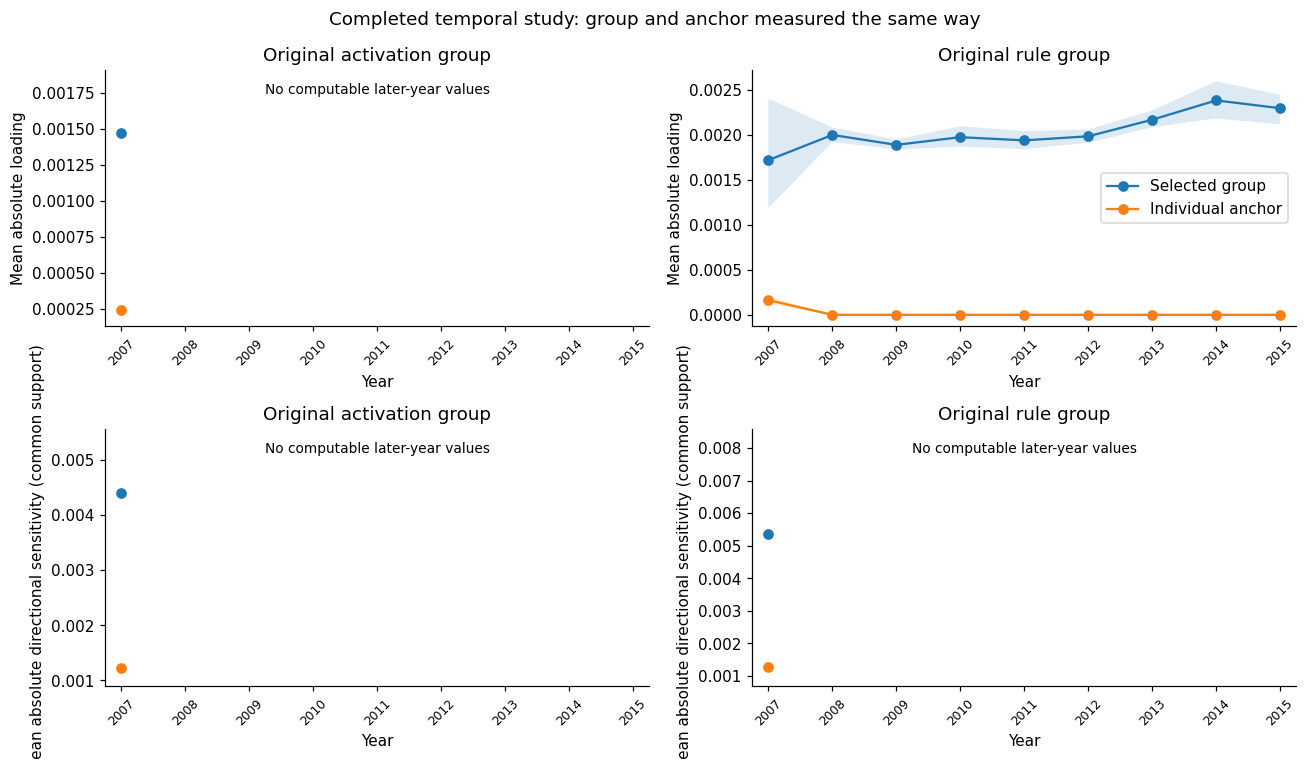

Reference 2007, concept 1, last 3 years; first case in structural order

In [7]:
display(Markdown(f"**{report_label}**"))
display(readable_table(report["families"]).head(30))
display(readable_table(report["annual"]).head(20))

example_annual = annual[
    (annual["concept"] == example_concept)
    & (annual["pair"] == example_pair)
    & (annual["side"] == example_side)
    & annual["kind"].isin(("selected", "singleton"))
]
required_direction_metric = "common_active_absolute_direction"
if required_direction_metric not in set(example_annual["metric"]):
    raise ValueError(
        "This result lacks the common-active group/anchor directional comparison. "
        "Do not substitute each method's own-active mean."
    )
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row, (metric, caption) in enumerate((
    ("absolute_loading", "Mean absolute loading"),
    ("common_active_absolute_direction", "Mean absolute directional sensitivity (common support)"),
)):
    for column, subgroup in enumerate(("A", "R")):
        axis = axes[row, column]
        panel = example_annual[
            (example_annual["metric"] == metric) & (example_annual["subgroup"] == subgroup)
        ]
        for kind, curve in panel.groupby("kind", sort=True):
            curve = curve.sort_values("year")
            axis.plot(curve["year"], curve["value"], marker="o", label=kind_labels[kind])
            axis.fill_between(curve["year"], curve["low"], curve["high"], alpha=0.15)
        axis.set(title=subgroup_labels[subgroup], xlabel="Year", ylabel=caption)
        axis.set_xlim(example_first_year - 0.25, example_last_year + 0.25)
        axis.set_xticks(example_year_ticks)
        axis.tick_params(axis="x", labelrotation=45, labelsize=8)
        later_values = panel.loc[panel["year"] > example_first_year, "value"]
        if not np.isfinite(later_values).any():
            axis.text(
                0.5, 0.95, "No computable later-year values",
                transform=axis.transAxes, ha="center", va="top", fontsize=9,
            )
axes[0, -1].legend()
fig.suptitle(f"{report_label}: group and anchor measured the same way")
fig.tight_layout()
plt.show()
display(Markdown(example_caption))

## Can a group hide changes in its members?

Inspect every member's activation and signed loading alongside the group's sum. Members can move
in opposite directions, producing a stable aggregate. Such stability is descriptive evidence about
cancellation, not automatically evidence of a better explanation. Examples below are selected by
structural order, without choosing favorable effects.

**Completed temporal study**

,Concept,Defined draws,Factor,High,Kind,Low,Metric,Pair,Reference,Rows,Side,Subgroup,Undefined draw fraction,Value,Variants,Year
0,"Reference 2008, concept 1",500,0,4.2451e-01,Selected group,2.8348e-01,activation,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,3.4881e-01,"Last 3 years, All previous years",2008
1,"Reference 2008, concept 1",500,0,-1.2131e-05,Selected group,-2.5592e-05,Mean signed loading,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,-1.8805e-05,"Last 3 years, All previous years",2008
2,"Reference 2008, concept 1",500,0,2.9381e-05,Selected group,1.6424e-05,Mean absolute loading,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,2.2792e-05,"Last 3 years, All previous years",2008
3,"Reference 2008, concept 1",500,63,5.1974e-01,Selected group,3.4970e-01,activation,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,4.3591e-01,"Last 3 years, All previous years",2008
4,"Reference 2008, concept 1",500,63,6.3057e-04,Selected group,3.9826e-04,Mean signed loading,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,5.1379e-04,"Last 3 years, All previous years",2008
5,"Reference 2008, concept 1",500,63,6.3057e-04,Selected group,3.9826e-04,Mean absolute loading,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,5.1379e-04,"Last 3 years, All previous years",2008
6,"Reference 2008, concept 1",500,92,6.9650e-01,Selected group,4.5943e-01,activation,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,5.7579e-01,"Last 3 years, All previous years",2008
7,"Reference 2008, concept 1",500,92,3.3078e-03,Selected group,2.0517e-03,Mean signed loading,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,2.6562e-03,"Last 3 years, All previous years",2008
8,"Reference 2008, concept 1",500,92,3.3078e-03,Selected group,2.0517e-03,Mean absolute loading,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,2.6562e-03,"Last 3 years, All previous years",2008
9,"Reference 2008, concept 1",500,132,4.4157e-01,Selected group,3.1446e-01,activation,Comparison 2,2008,298,First dictionary,All evaluation patients,0.0,3.7883e-01,"Last 3 years, All previous years",2008


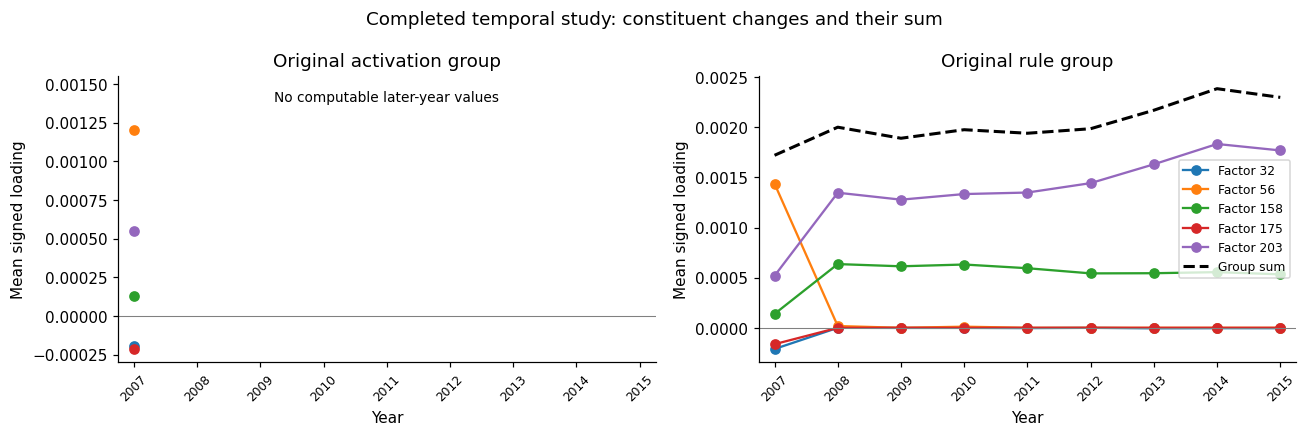

Reference 2007, concept 1, last 3 years; first case in structural order

In [8]:
display(Markdown(f"**{report_label}**"))
display(readable_table(report["members"]).head(30))

members = report["members"]
example_members = members[
    (members["concept"] == example_concept)
    & (members["pair"] == example_pair)
    & (members["side"] == example_side)
    & (members["kind"] == "selected")
    & (members["metric"] == "signed_loading")
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, subgroup in zip(axes, ("A", "R")):
    panel = example_members[example_members["subgroup"] == subgroup]
    for factor, curve in panel.groupby("factor", sort=True):
        curve = curve.sort_values("year")
        axis.plot(curve["year"], curve["value"], marker="o", label=f"Factor {factor}")
    total = example_annual[
        (example_annual["kind"] == "selected")
        & (example_annual["subgroup"] == subgroup)
        & (example_annual["metric"] == "signed_loading")
    ].sort_values("year")
    axis.plot(total["year"], total["value"], color="black", linestyle="--", linewidth=2, label="Group sum")
    axis.axhline(0, color="grey", linewidth=0.7)
    axis.set(title=subgroup_labels[subgroup], xlabel="Year", ylabel="Mean signed loading")
    axis.set_xlim(example_first_year - 0.25, example_last_year + 0.25)
    axis.set_xticks(example_year_ticks)
    axis.tick_params(axis="x", labelrotation=45, labelsize=8)
    later_values = panel.loc[panel["year"] > example_first_year, "value"]
    if not np.isfinite(later_values).any():
        axis.text(
            0.5, 0.95, "No computable later-year values",
            transform=axis.transAxes, ha="center", va="top", fontsize=9,
        )
axes[-1].legend(fontsize=8)
fig.suptitle(f"{report_label}: constituent changes and their sum")
fig.tight_layout()
plt.show()
display(Markdown(example_caption))

## The same patients changing, or different patients appearing?

Adjacent-year comparisons first match patient identities. Missing observations are absent, never zero.
The returning-patient change is measured on the same patients at both ends; the composition part is
the full-population change minus that returning-patient change. Persistent membership and membership
transitions are reported separately.

For signed loading, the exact midpoint identity separates two terms:

**loading change = mean gradient · contribution change + mean contribution · gradient change.**

The predictor remains frozen. A change in its local gradient means it is evaluated at different
patient representations; it does not mean the predictor was retrained.

In [9]:
display(Markdown(f"**{report_label}**"))
display(readable_table(report["paired"]).head(30))
display(readable_table(report["transitions"]).head(30))

**Completed temporal study**

,Cohort absent after,Cohort absent before,Concept,Defined draws,High,Kind,Low,Metric,Pair,Reference,Returning rows,Side,Start,Subgroup,Subgroup absent after,Subgroup absent before,Undefined draw fraction,Value,Variants,Year
0,70,86,"Reference 2008, concept 1",500,2.4420e-03,Selected group,-0.0006,total absolute loading change,Comparison 2,2008,228,First dictionary,2008,All evaluation patients,70,86,0.0,8.7723e-04,"Last 3 years, All previous years",2009
1,70,86,"Reference 2008, concept 1",500,2.3029e-03,Selected group,-0.0007,returning absolute loading change,Comparison 2,2008,228,First dictionary,2008,All evaluation patients,70,86,0.0,8.7474e-04,"Last 3 years, All previous years",2009
2,70,86,"Reference 2008, concept 1",500,1.1438e-03,Selected group,-0.0011,composition absolute loading change,Comparison 2,2008,228,First dictionary,2008,All evaluation patients,70,86,0.0,2.4916e-06,"Last 3 years, All previous years",2009
3,65,84,"Reference 2008, concept 1",500,2.3968e-03,Selected group,-0.0007,total absolute loading change,Comparison 2,2008,249,First dictionary,2009,All evaluation patients,65,84,0.0,8.3115e-04,"Last 3 years, All previous years",2010
4,65,84,"Reference 2008, concept 1",500,2.1993e-03,Selected group,-0.0003,returning absolute loading change,Comparison 2,2008,249,First dictionary,2009,All evaluation patients,65,84,0.0,9.1781e-04,"Last 3 years, All previous years",2010
5,65,84,"Reference 2008, concept 1",500,1.0534e-03,Selected group,-0.0012,composition absolute loading change,Comparison 2,2008,249,First dictionary,2009,All evaluation patients,65,84,0.0,-8.6653e-05,"Last 3 years, All previous years",2010
6,122,114,"Reference 2008, concept 1",500,2.3546e-03,Selected group,-0.0010,total absolute loading change,Comparison 2,2008,211,First dictionary,2010,All evaluation patients,122,114,0.0,7.5091e-04,"Last 3 years, All previous years",2011
7,122,114,"Reference 2008, concept 1",500,1.5309e-03,Selected group,-0.0018,returning absolute loading change,Comparison 2,2008,211,First dictionary,2010,All evaluation patients,122,114,0.0,1.1566e-06,"Last 3 years, All previous years",2011
8,122,114,"Reference 2008, concept 1",500,2.0029e-03,Selected group,-0.0007,composition absolute loading change,Comparison 2,2008,211,First dictionary,2010,All evaluation patients,122,114,0.0,7.4975e-04,"Last 3 years, All previous years",2011
9,81,66,"Reference 2008, concept 1",500,1.2887e-03,Selected group,-0.0018,total absolute loading change,Comparison 2,2008,244,First dictionary,2011,All evaluation patients,81,66,0.0,-1.3503e-04,"Last 3 years, All previous years",2012


,Cohort absent after,Cohort absent before,Concept,Defined draws,High,Kind,Low,Metric,Pair,Reference,...,Side,Start,Subgroup,Subgroup absent after,Subgroup absent before,Transition,Undefined draw fraction,Value,Variants,Year
0,70,86,"Reference 2008, concept 1",500,0.0023,Selected group,-6.9286e-04,loading change,Comparison 2,2008,...,First dictionary,2008,All evaluation patients,70,86,Stayed in subgroup,0.0,0.0009,"Last 3 years, All previous years",2009
1,70,86,"Reference 2008, concept 1",500,0.0023,Selected group,6.2674e-04,contribution change,Comparison 2,2008,...,First dictionary,2008,All evaluation patients,70,86,Stayed in subgroup,0.0,0.0015,"Last 3 years, All previous years",2009
2,70,86,"Reference 2008, concept 1",500,0.0001,Selected group,-1.3705e-03,gradient change,Comparison 2,2008,...,First dictionary,2008,All evaluation patients,70,86,Stayed in subgroup,0.0,-0.0006,"Last 3 years, All previous years",2009
3,70,86,"Reference 2008, concept 1",500,0.0023,Selected group,-6.9286e-04,absolute loading change,Comparison 2,2008,...,First dictionary,2008,All evaluation patients,70,86,Stayed in subgroup,0.0,0.0009,"Last 3 years, All previous years",2009
4,70,86,"Reference 2008, concept 1",0,NaN,Selected group,NaN,loading change,Comparison 2,2008,...,First dictionary,2008,All evaluation patients,70,86,Left subgroup,1.0,NaN,"Last 3 years, All previous years",2009
5,70,86,"Reference 2008, concept 1",0,NaN,Selected group,NaN,contribution change,Comparison 2,2008,...,First dictionary,2008,All evaluation patients,70,86,Left subgroup,1.0,NaN,"Last 3 years, All previous years",2009
6,70,86,"Reference 2008, concept 1",0,NaN,Selected group,NaN,gradient change,Comparison 2,2008,...,First dictionary,2008,All evaluation patients,70,86,Left subgroup,1.0,NaN,"Last 3 years, All previous years",2009
7,70,86,"Reference 2008, concept 1",0,NaN,Selected group,NaN,absolute loading change,Comparison 2,2008,...,First dictionary,2008,All evaluation patients,70,86,Left subgroup,1.0,NaN,"Last 3 years, All previous years",2009
8,70,86,"Reference 2008, concept 1",0,NaN,Selected group,NaN,loading change,Comparison 2,2008,...,First dictionary,2008,All evaluation patients,70,86,Entered subgroup,1.0,NaN,"Last 3 years, All previous years",2009
9,70,86,"Reference 2008, concept 1",0,NaN,Selected group,NaN,contribution change,Comparison 2,2008,...,First dictionary,2008,All evaluation patients,70,86,Entered subgroup,1.0,NaN,"Last 3 years, All previous years",2009


## Follow the original subgroup, with attrition shown

This companion view follows patients who belonged to the original reference-year subgroup, regardless
of their later activation or rule membership. Its observed support falls when patients no longer have
a row. Keep this fixed starting cohort separate from the annually redefined subgroup; each answers
a different question.

In [10]:
display(Markdown(f"**{report_label}**"))
display(readable_table(report["fixed_cohort"]).head(30))

**Completed temporal study**

,Concept,Defined draws,High,Kind,Low,Metric,Pair,Reference,Reference rows,Retained fraction,Rows,Side,Subgroup,Undefined draw fraction,Value,Variants,Year
0,"Reference 2008, concept 1",500,0.0063,Selected group,0.0041,Mean absolute loading,Comparison 2,2008,298,1.0000,298,First dictionary,All evaluation patients,0.0,0.0052,"Last 3 years, All previous years",2008
1,"Reference 2008, concept 1",500,0.0059,Selected group,0.0037,Mean absolute loading,Comparison 2,2008,298,0.7651,228,First dictionary,All evaluation patients,0.0,0.0048,"Last 3 years, All previous years",2009
2,"Reference 2008, concept 1",500,0.0060,Selected group,0.0037,Mean absolute loading,Comparison 2,2008,298,0.6946,207,First dictionary,All evaluation patients,0.0,0.0048,"Last 3 years, All previous years",2010
3,"Reference 2008, concept 1",500,0.0056,Selected group,0.0036,Mean absolute loading,Comparison 2,2008,298,0.5034,150,First dictionary,All evaluation patients,0.0,0.0045,"Last 3 years, All previous years",2011
4,"Reference 2008, concept 1",500,0.0064,Selected group,0.0039,Mean absolute loading,Comparison 2,2008,298,0.4195,125,First dictionary,All evaluation patients,0.0,0.0051,"Last 3 years, All previous years",2012
5,"Reference 2008, concept 1",500,0.0066,Selected group,0.0044,Mean absolute loading,Comparison 2,2008,298,0.3792,113,First dictionary,All evaluation patients,0.0,0.0055,"Last 3 years, All previous years",2013
6,"Reference 2008, concept 1",500,0.0072,Selected group,0.0048,Mean absolute loading,Comparison 2,2008,298,0.3557,106,First dictionary,All evaluation patients,0.0,0.0061,"Last 3 years, All previous years",2014
7,"Reference 2008, concept 1",500,0.0090,Selected group,0.0061,Mean absolute loading,Comparison 2,2008,298,0.3289,98,First dictionary,All evaluation patients,0.0,0.0074,"Last 3 years, All previous years",2015
8,"Reference 2008, concept 1",500,0.0260,Selected group,0.0182,Mean absolute loading,Comparison 2,2008,45,1.0000,45,First dictionary,Original activation group,0.0,0.0224,"Last 3 years, All previous years",2008
9,"Reference 2008, concept 1",500,0.0087,Selected group,0.0025,Mean absolute loading,Comparison 2,2008,45,0.6667,30,First dictionary,Original activation group,0.0,0.0052,"Last 3 years, All previous years",2009


## Do sensitivity changes accompany performance changes?

These are same-period descriptive associations, not forecasts or causal effects. The primary series
uses changes in mean absolute loading and Brier on the same original subgroup rows through 2014.
Directional sensitivity is secondary, and its Brier series uses the exact same common-active support.

The source study found that absolute CAV sensitivity tracked predicted risk closely: its association
with Brier largely disappeared after adjusting for mean predicted risk. Its later follow-up compared
probability-gradient and log-odds-gradient sensitivity, including risk and predictor-year controls.
The interpretation changed with sensitivity scale and with shared time trends across a predictor's
concepts. Neither scale gave clear evidence of performance information beyond predicted risk.
These are findings of the source follow-up, not new log-odds calculations in this extension.

The approved extension includes adjustments for mean predicted risk and the available concept,
time, mortality and subgroup-size controls; inspect the adjustment labels and supported rows.
A pooled association can reflect predictor-wide movement over time, so it does not by itself
establish concept-specific influence or show that grouping adds information. Within-concept
correlations require at least three varying, computable transitions; sparse or constant series
remain unsupported.

**Association calculation correction.** After the full scoring run, an association-only calculation
was corrected. Some concepts disappeared when rows with missing measures were removed, leaving
unused concept-indicator columns in the adjustment matrix. Those columns made otherwise usable
adjustments appear undefined. The completed correction uses the effective rank of the control space, so unused or redundant
indicator columns no longer force an undefined result. All control columns are retained; the
adjustment choices are unchanged. Association estimates and intervals are recomputed from the
saved aggregate patient draws.
It does not rescore patients, refit groups, or overwrite the original scoring outputs. The report
loader uses the separate correction only after validating its manifest and hashes. The appendix
shows that provenance explicitly.

The association tables' **available year-pairs** count is the possible panel before rows with missing
measures are removed; it is not the number used in each correlation. Actual finite support can be
smaller. For the primary selected-group loading analysis, 166 of 210 possible year-pairs are finite
in the activation group and 208 of 210 in the rule group; they cover 54 and 60 observed concepts,
respectively. The corresponding common-active directional analyses have 166 and 192 finite pairs.
Bootstrap draws can have different finite support.

In [11]:
display(Markdown(f"**{report_label}**"))
display(readable_table(report["associations"]))

**Completed temporal study**

,Adjustment,Concept,Defined draws,Concepts in available panel,Feature,High,Kind,Level,Low,Metric,Reference,Subgroup,Target,Available year-pairs before missing-value filtering,Undefined draw fraction,Value,Variant,Variants
0,No adjustment,"Reference 2008, concept 1",500,NaN,Mean absolute loading,0.8857,Selected group,Year-to-year changes within this concept,-0.6571,Rank correlation,2008.0,All evaluation patients,brier,6,0.000,0.6000,NaN,"Last 3 years, All previous years"
1,"Adjusted for mortality, mean risk and subgroup...","Reference 2008, concept 1",3,NaN,Mean absolute loading,-0.0401,Selected group,Year-to-year changes within this concept,-0.6693,Rank correlation,2008.0,All evaluation patients,brier,6,0.994,NaN,NaN,"Last 3 years, All previous years"
2,No adjustment,"Reference 2008, concept 1",500,NaN,Mean absolute directional sensitivity (common ...,0.8857,Selected group,Year-to-year changes within this concept,-0.4286,Rank correlation,2008.0,All evaluation patients,common active brier,6,0.000,0.4286,NaN,"Last 3 years, All previous years"
3,"Adjusted for mortality, mean risk and subgroup...","Reference 2008, concept 1",5,NaN,Mean absolute directional sensitivity (common ...,0.6755,Selected group,Year-to-year changes within this concept,-0.3446,Rank correlation,2008.0,All evaluation patients,common active brier,6,0.990,NaN,NaN,"Last 3 years, All previous years"
4,No adjustment,"Reference 2008, concept 1",500,NaN,Mean absolute loading,0.8286,Selected group,Year-to-year changes within this concept,-0.7714,Rank correlation,2008.0,Original activation group,brier,6,0.000,0.2571,NaN,"Last 3 years, All previous years"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2299,Also adjusted for mean predicted risk,All concepts,500,61.0,Mean absolute directional sensitivity (common ...,0.1821,Individual anchor,Year-to-year changes across concepts,-0.3044,Rank correlation,NaN,Original rule group,common active brier,210,0.000,-0.0074,Last 3 years,NaN
2300,No adjustment,All concepts,500,51.0,Mean absolute directional sensitivity (common ...,0.3158,Individual anchor,Year-to-year changes across concepts,0.0253,Rank correlation,NaN,Original rule group,common active brier,190,0.000,0.1906,All previous years,NaN
2301,Adjusted for concept and year,All concepts,500,51.0,Mean absolute directional sensitivity (common ...,0.3593,Individual anchor,Year-to-year changes across concepts,-0.0137,Rank correlation,NaN,Original rule group,common active brier,190,0.000,0.1279,All previous years,NaN
2302,"Adjusted for concept, year, mortality and subg...",All concepts,500,51.0,Mean absolute directional sensitivity (common ...,0.4259,Individual anchor,Year-to-year changes across concepts,-0.0005,Rank correlation,NaN,Original rule group,common active brier,190,0.000,0.2091,All previous years,NaN


### Whole-study association with concurrent performance

These panels show the saved primary-context pooled correlations between **year-to-year sensitivity
changes and Brier changes**, separately for the original activation and rule groups. Group and anchor
use the same definitions. Directional sensitivity and its Brier companion use the same common-active
patients. Compare unadjusted estimates with the saved adjustments for concept, year, mortality,
subgroup size and mean predicted risk.

A positive correlation means larger sensitivity changes accompany larger Brier changes. Each line is
a separate estimate: visual differences between group and anchor are **not a test of their difference**.
Neither correlation nor adjustment establishes a causal or concept-specific influence. Undefined
estimates and sparse support remain visible.

Plot support labels show the available panel before missing-value filtering, not the final sample
used in the estimate. Read the method note above and the correction manifest for finite-support
checks. Corrected estimates are loaded from the separate association-correction directory.

**Completed temporal study**

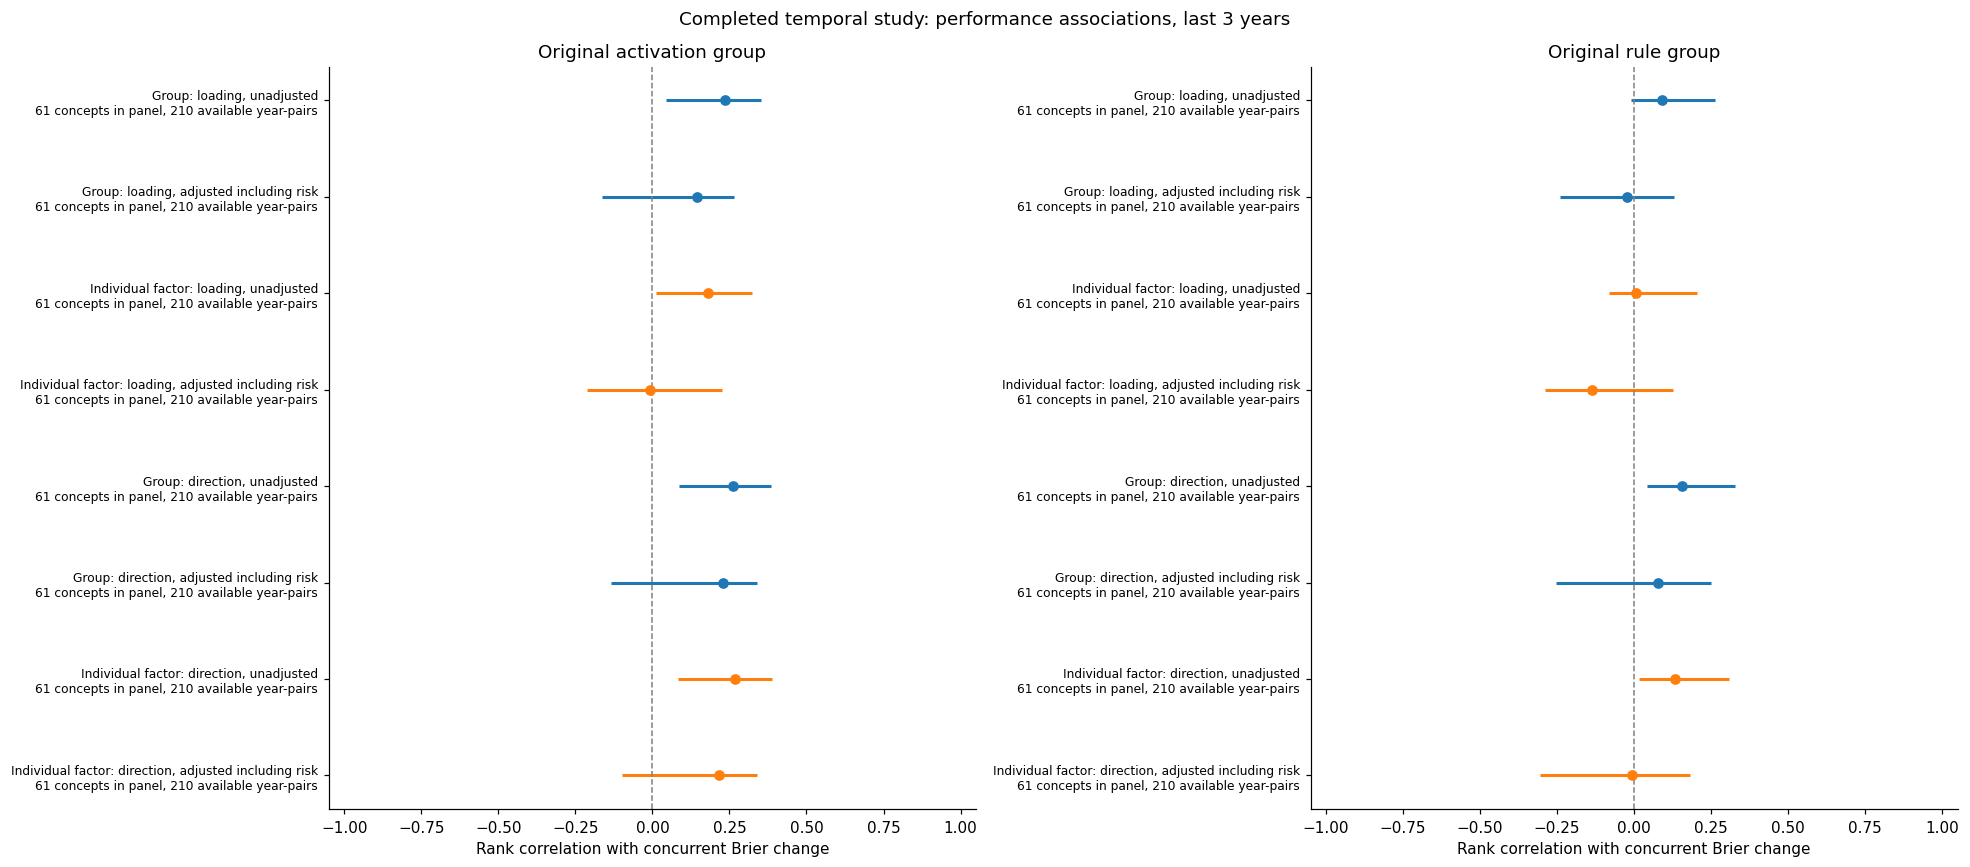

Points are saved estimates; lines are 95% intervals from shared patient draws. These are related descriptive estimates, not independent replications or group-versus-anchor difference tests.

In [12]:
display(Markdown(f"**{report_label}**"))
associations = report["associations"]
primary_associations = associations[
    (associations["level"] == "pooled_changes") & (associations["variant"] == "last_3")
]
association_features = (
    ("absolute_loading", "brier", "Loading"),
    ("common_active_absolute_direction", "common_active_brier", "Direction"),
)
association_adjustments = (
    ("none", "unadjusted"),
    ("family_year_mortality_risk_and_support", "adjusted including risk"),
)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for axis, subgroup in zip(axes, ("A", "R")):
    labels = []
    position = 0
    for feature, target, feature_label in association_features:
        for kind, method in (("selected", "Group"), ("singleton", "Individual factor")):
            for adjustment, adjustment_label in association_adjustments:
                matching = primary_associations[
                    (primary_associations["subgroup"] == subgroup)
                    & (primary_associations["feature"] == feature)
                    & (primary_associations["target"] == target)
                    & (primary_associations["kind"] == kind)
                    & (primary_associations["adjustment"] == adjustment)
                ]
                if len(matching) > 1:
                    raise ValueError("Expected one saved pooled estimate per method and adjustment.")
                label = f"{method}: {feature_label.lower()}, {adjustment_label}"
                if matching.empty:
                    labels.append(f"{label}\nSupport not recorded")
                    axis.text(0.02, position, "Not available", transform=axis.get_yaxis_transform(), va="center")
                    position += 1
                    continue
                estimate = matching.iloc[0]
                transitions, concepts = estimate["transitions"], estimate["families"]
                if pd.notna(transitions) and pd.notna(concepts):
                    label += f"\n{int(concepts)} concepts in panel, {int(transitions)} available year-pairs"
                labels.append(label)
                colour = "tab:blue" if kind == "selected" else "tab:orange"
                if np.isfinite(estimate["low"]) and np.isfinite(estimate["high"]):
                    axis.hlines(position, estimate["low"], estimate["high"], color=colour, linewidth=2)
                if np.isfinite(estimate["value"]):
                    axis.scatter(estimate["value"], position, color=colour, zorder=3)
                else:
                    axis.text(0.02, position, "Undefined", transform=axis.get_yaxis_transform(), va="center")
                position += 1
    axis.axvline(0, color="grey", linestyle="--", linewidth=1)
    axis.set_yticks(range(len(labels)), labels, fontsize=8)
    axis.invert_yaxis()
    axis.set_xlim(-1.05, 1.05)
    axis.set(title=subgroup_labels[subgroup], xlabel="Rank correlation with concurrent Brier change")
fig.suptitle(f"{report_label}: performance associations, last 3 years")
fig.tight_layout()
plt.show()
display(Markdown(
    "Points are saved estimates; lines are 95% intervals from shared patient draws. "
    "These are related descriptive estimates, not independent replications or group-versus-anchor difference tests."
))

## Read the evidence together

Use the saved summaries to answer three separate questions:

1. Does grouping preserve similar represented contributions across dictionaries in later years, beyond the controls?
2. Does it reveal consistent sensitivity changes while keeping member disagreement and patient composition visible?
3. Do those changes add descriptive information about concurrent performance after considering risk level and support?

A yes to the first question does not establish the second or third. A narrow interval conditional on
frozen objects does not remove uncertainty about choosing those objects. No automatic replacement
of individual-factor explanations follows from these summaries.

Interpret sensitivity results on their stated probability scale. Risk adjustments help assess shared
risk patterns; they do not convert the measurements to log odds or establish a mechanism. Pooled
changes shared across a predictor's concepts must not be described as concept-specific influence.

In [13]:
display(Markdown(f"**{report_label}**"))
if is_smoke:
    display(Markdown(
        "**Scientific answers are pending.** This is a bounded smoke check, not the full inventory."
    ))
else:
    display(readable_table(report["summary"]))

**Completed temporal study**

,Cases computable,Cases total,Concept,Defined draws,High,Later years,Level,Low,Metric,Pair,Patient draws shared across cases,Reference,Subgroup,Undefined draw fraction,Value,Variant,Variants
0,NaN,NaN,"Reference 2008, concept 1",500,-0.1800,7.0,Average over later years for this comparison,-0.2005,Selected group minus individual anchor disagre...,Comparison 2,NaN,2008.0,All evaluation patients,0.0,-0.1904,NaN,"Last 3 years, All previous years"
1,NaN,NaN,"Reference 2008, concept 1",500,0.2605,7.0,Average over later years for this comparison,0.2379,Selected group minus matched control 1 disagre...,Comparison 2,NaN,2008.0,All evaluation patients,0.0,0.2489,NaN,"Last 3 years, All previous years"
2,NaN,NaN,"Reference 2008, concept 1",500,0.0513,7.0,Average over later years for this comparison,0.0229,Selected group minus matched control 2 disagre...,Comparison 2,NaN,2008.0,All evaluation patients,0.0,0.0367,NaN,"Last 3 years, All previous years"
3,NaN,NaN,"Reference 2008, concept 1",500,-0.0234,7.0,Average over later years for this comparison,-0.0532,Selected group minus matched control 3 disagre...,Comparison 2,NaN,2008.0,All evaluation patients,0.0,-0.0383,NaN,"Last 3 years, All previous years"
4,NaN,NaN,"Reference 2008, concept 1",500,-0.3593,7.0,Average over later years for this comparison,-0.3762,Selected group minus individual anchor disagre...,Comparison 2,NaN,2008.0,Original activation group,0.0,-0.3690,NaN,"Last 3 years, All previous years"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3331,153.0,153.0,NaN,500,-0.1981,NaN,Median across related comparisons,-0.2199,Selected group minus matched control 1 disagre...,NaN,True,NaN,Original rule group,0.0,-0.2087,All previous years,NaN
3332,180.0,183.0,NaN,500,-0.1583,NaN,Median across related comparisons,-0.1725,Selected group minus matched control 2 disagre...,NaN,True,NaN,Original rule group,0.0,-0.1647,Last 3 years,NaN
3333,153.0,153.0,NaN,500,-0.1742,NaN,Median across related comparisons,-0.1861,Selected group minus matched control 2 disagre...,NaN,True,NaN,Original rule group,0.0,-0.1789,All previous years,NaN
3334,180.0,183.0,NaN,500,-0.1763,NaN,Median across related comparisons,-0.1978,Selected group minus matched control 3 disagre...,NaN,True,NaN,Original rule group,0.0,-0.1813,Last 3 years,NaN


## Findings from the completed 92-concept study

These recorded findings describe the completed full run named in the provenance appendix. Selecting
another results folder changes the tables and plots but does not recompute this narrative.

### 1. What was run, and did the original study reproduce?

All **92 concepts with saved groups** were scored, giving **276 dictionary-pair comparisons**.
Three of the source study's 95 concepts had no saved group definition and remain explicit gaps.
The full scoring run took about **22 minutes on Fiji's GPU**. The 2,760 reference-year checks
reproduced the earlier representation measurements, with largest absolute difference below
9 × 10⁻¹⁶. All 242 recorded consumed-input hashes were preserved. The association correction
below is a separate analysis of the saved results; it does not alter these scoring outputs.

### 2. Do the groups preserve representation in later years?

**Yes, consistently relative to individual anchors.** The primary context contains 61 concepts,
each with three dictionary comparisons: 183 possible cases. Each case first averages its
computable later-year differences; the table then summarizes across those related cases.

| Evaluation population | Median group-minus-anchor disagreement, with 95% interval | Computable cases | Cases favoring the group |
|---|---|---|---|
| All evaluation patients | −0.370 [−0.377, −0.367] | 181 / 183 | 179 / 181 |
| Original activation group | −0.449 [−0.453, −0.446] | 162 / 183 | 162 / 162 |
| Original rule group | −0.440 [−0.443, −0.432] | 178 / 183 | 178 / 178 |

Negative means the two dictionaries' represented contributions are closer for the group than for
the individual anchor. These are differences on the disagreement scale, not percentages. Missing
or zero-signal comparisons are not evidence of no difference. The all-previous-years context
shows the same general pattern. Patient-bootstrap intervals condition on the frozen objects;
shared patients and overlapping concepts make the cases dependent.

### 3. Is this more than a benefit from combining arbitrary factors?

**There is supporting evidence, especially inside the original activation and rule groups, but
specificity is incomplete.** Compared separately with each of the three matched control series,
the selected groups have a lower median later-year disagreement. These median advantages are
about 0.030–0.044 across all patients, 0.147–0.185 in the activation group and 0.165–0.181 in the
rule group.

A stricter question is whether a selected group beats **all three controls in the same case**.
It does so in 67 / 183 complete cases across all patients, 100 / 160 in the activation group and
108 / 180 in the rule group. This differs from comparing a median with each control series:
the strongest control can change from case to case. Neither result establishes a unique clinical
meaning for the groups or justifies replacing individual explanations by default.

### 4. What must remain visible when reading sensitivity and patient changes?

The main loading analysis retains all original subgroup rows. Normalized directional sensitivity
has more restricted support: the median common-active fraction is about **30.2% of all evaluation
patients**, **100% within nonempty activation groups** and **98.0% within nonempty rule groups**.
An apparently broad whole-cohort directional result therefore describes a selected subset.

Among 332 primary concept-year cells, 56 activation-group cells have no common-active support;
55 of those groups are already empty. The corresponding counts are 25 rule-group cells, including
five empty groups, and 20 whole-cohort cells. These cells remain undefined rather than becoming zero.

The reported geometric cancellation is about 39.5% in activation groups and 38.5% in rule groups,
using the median of the family-year means. This describes **vector length shrinking when member
contributions are added**. It is not a percentage of cancelled mortality risk and does not by itself
prove opposing prediction effects. Member trajectories remain necessary. Likewise, a returning-
patient component can include activation or rule membership changes among returners; it is not
identical to a response change among patients who stay in the subgroup.

### 5. Do groups explain concurrent performance changes beyond individual factors?

**A clear, consistent performance association beyond the stated controls was not demonstrated.**
The corrected primary-context results below relate same-period sensitivity changes to Brier changes,
with concept, year, mortality, subgroup size and mean predicted risk included in the adjustment.
All four group intervals include zero; all 500 shared patient-bootstrap draws are defined.

| Selected-group measure | Original activation group: rank correlation [95% interval] | Original rule group: rank correlation [95% interval] |
|---|---|---|
| Mean absolute loading | 0.145 [−0.164, 0.263] | −0.024 [−0.239, 0.131] |
| Mean absolute directional sensitivity, common-active patients | 0.229 [−0.135, 0.341] | 0.078 [−0.255, 0.251] |

The anchor estimates are also mixed and uncertain, with intervals including zero. The
all-previous-years companion gives the same overall conclusion for the groups: every main adjusted
interval includes zero. This does not prove that the associations are exactly zero. Nor is it a
formal test of a group-versus-anchor difference or a forecasting test.

The association-only correction completed successfully. All 112,800 saved trajectory vectors were
unchanged; it corrected how the adjustment matrix handles concepts absent after missing-value
filtering. Its separate manifest identifies the corrected estimates. The original patient scoring,
representation results and raw output files were preserved.

Frozen predictions are identical under the group and individual descriptions: their Brier scores on
identical patients differ by exactly zero in the saved results. This extension therefore does not
establish a predictive improvement from grouping. Loading and directional sensitivity remain
probability-gradient measurements; unit normalization removes neither risk dependence nor the
probability-scale factor. Shared predictor-wide movement over time is not concept-specific influence.

**The practical answer:** groups provide strong, consistent later-year representation benefits
across dictionaries and are useful for studying joint behavior alongside individual members.
Keep member trajectories, geometric cancellation, patient composition and common-active support
visible. Added usefulness for explaining concurrent performance beyond the stated controls has
not been shown, and these results do not justify replacing individual-factor explanations by default.

## Provenance and resource use

The appendix records the run manifest, source fingerprints, reference checks, device and resource
measurements. Private patient identities, embeddings, gradients, codes and contribution vectors stay
on Fiji. The original study is preserved; all new artifacts belong to this extension's output folder.

The association-only correction has its own `association-correction/correction-manifest.json`.
Its source hash, input hashes and corrected-output hashes document which calculations were changed;
the original full-run manifest and scoring tables remain available alongside it.

The recorded findings above describe the full run `20261108-full` under
`analysis_outputs/concept_groups_over_time/`. The manifest displayed below belongs to the currently
selected results folder, which can differ if another folder is explicitly selected.

In [14]:
display(Markdown(f"**{report_label}**"))
display(pd.json_normalize(manifest).T.rename(columns={0: "recorded value"}))
for filename in ("stages.json", "reference_checks.json", "source_integrity.json", "gpu_utilization.json"):
    evidence_path = result_directory / filename
    if evidence_path.exists():
        display(Markdown(f"**{filename}**"))
        display(JSON(json.loads(evidence_path.read_text())))

display(Markdown("**Raw identifiers for tracing the readable concept and comparison labels**"))
display(report["inventory"])


correction_manifest_path = result_directory / "association-correction" / "correction-manifest.json"
if correction_manifest_path.exists():
    display(Markdown("**Association-only correction: provenance and validation**"))
    display(JSON(json.loads(correction_manifest_path.read_text())))
else:
    display(Markdown("**No association-correction manifest is present in this result directory.**"))


**Completed temporal study**

,recorded value
amp,off
base_git_sha,16425eebff2d991e6b7cb053c6c17ba4bd3d25bf
bootstrap_draws,500
command,/home/rafaelgomes/SAE-TCAV/analysis_outputs/co...
completed_families,92
...,...
input_sha256./home/rafaelgomes/rpi-runs/SAE-TCAV/r1-pilot-fe945-20261009/unit-cache/c71b8d1d7d28bebb6947317fefc0b9fe4891e937ba97e356b9745f929e3e7b02/units/S/42/2007/meta.json,eec183f491cab7b73570ea7d5ed6763c92cc4aab936624...
packages.numpy,1.26.4
packages.pandas,2.3.3
packages.scipy,1.15.3


**stages.json**

<IPython.core.display.JSON object>

**reference_checks.json**

<IPython.core.display.JSON object>

... (4 outputs left out)

**Raw identifiers for tracing the readable concept and comparison labels**

,build,concept,family,key,pair,reference,selected,status,variants
0,all_history,"all_history/2008/2008/42/42:0,135:24,215:233","2008/42/42:0,135:24,215:233","all_history/2008/2008/42/42:0,135:24,215:233/4...",42-135,2008,True,available,"last_3,all_history"
1,all_history,"all_history/2008/2008/42/42:0,135:24,215:233","2008/42/42:0,135:24,215:233","all_history/2008/2008/42/42:0,135:24,215:233/4...",42-215,2008,True,available,"last_3,all_history"
2,all_history,"all_history/2008/2008/42/42:0,135:24,215:233","2008/42/42:0,135:24,215:233","all_history/2008/2008/42/42:0,135:24,215:233/1...",135-215,2008,True,available,"last_3,all_history"
3,all_history,"all_history/2008/2008/42/42:142,135:265,215:184","2008/42/42:142,135:265,215:184","all_history/2008/2008/42/42:142,135:265,215:18...",42-135,2008,True,available,"last_3,all_history"
4,all_history,"all_history/2008/2008/42/42:142,135:265,215:184","2008/42/42:142,135:265,215:184","all_history/2008/2008/42/42:142,135:265,215:18...",42-215,2008,True,available,"last_3,all_history"
...,...,...,...,...,...,...,...,...,...
280,r1,"r1/2007/2007/42/42:65,135:187,215:78","2007/42/42:65,135:187,215:78","r1/2007/2007/42/42:65,135:187,215:78/42-215",42-215,2007,True,available,"last_3,all_history"
281,r1,"r1/2007/2007/42/42:65,135:187,215:78","2007/42/42:65,135:187,215:78","r1/2007/2007/42/42:65,135:187,215:78/135-215",135-215,2007,True,available,"last_3,all_history"
282,r1,"r1/2007/2007/42/42:94,135:3,215:146","2007/42/42:94,135:3,215:146","r1/2007/2007/42/42:94,135:3,215:146/42-135",42-135,2007,True,available,"last_3,all_history"
283,r1,"r1/2007/2007/42/42:94,135:3,215:146","2007/42/42:94,135:3,215:146","r1/2007/2007/42/42:94,135:3,215:146/42-215",42-215,2007,True,available,"last_3,all_history"


**Association-only correction: provenance and validation**

<IPython.core.display.JSON object>